Method of moments for a Gaussian (Victor Z, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $x_\omega$, $S$ | `x_omega`, `S` | data and sample size |
| $\hat{\mathbb{E}}_X$, $\hat{\mathbb{V}}_X$ | `E_hat`, `V_hat` | sample mean and variance |
| $\hat{\mu}=\hat{\mathbb{E}}_X$, $\hat{\sigma}^2=\hat{\mathbb{V}}_X$ | `mu_hat`, `sigma_hat` | moment-matching estimates |

Data are drawn from $\mathcal{N}(1, 2^2)$; results differ slightly from the Matlab
version because the random samples differ.

S =  10:  mu_hat = 0.81,  sigma_hat = 2.38
S = 100:  mu_hat = 1.12,  sigma_hat = 1.77


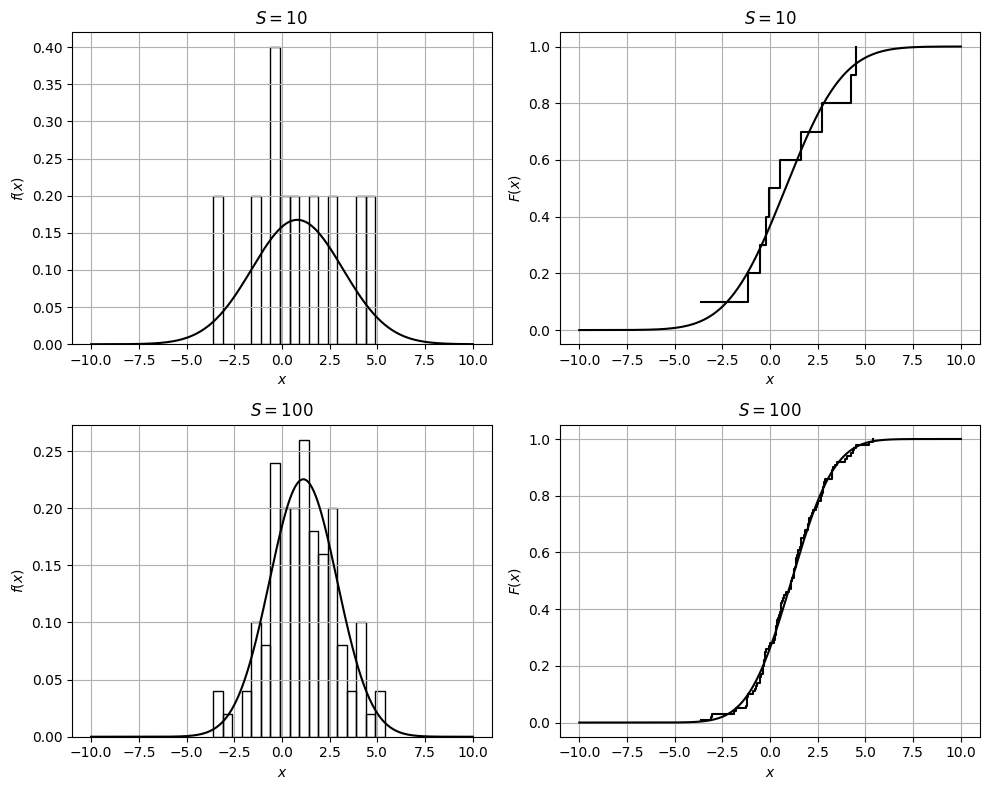

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu_true, sigma_true = 1, 2
x = np.linspace(-10, 10, 400)

fig, axs = plt.subplots(2, 2, figsize=(10, 8))
for row, S in enumerate((10, 100)):
    np.random.seed(1)
    x_omega = np.random.normal(mu_true, sigma_true, S)

    E_hat = np.sum(x_omega) / S
    V_hat = np.sum((x_omega - E_hat)**2) / S
    mu_hat, sigma_hat = E_hat, np.sqrt(V_hat)      # match CMO_1 and CMO_2
    print(f"S = {S:3d}:  mu_hat = {mu_hat:.2f},  sigma_hat = {sigma_hat:.2f}")

    axs[row, 0].hist(x_omega, bins=np.arange(x_omega.min(), x_omega.max() + 0.5, 0.5),
                     density=True, edgecolor='black', facecolor='none')
    axs[row, 0].plot(x, norm.pdf(x, mu_hat, sigma_hat), 'k', linewidth=1.5)
    axs[row, 0].set_ylabel('$f(x)$')
    axs[row, 1].step(np.sort(x_omega), np.arange(1, S + 1) / S, where='post', color='black')
    axs[row, 1].plot(x, norm.cdf(x, mu_hat, sigma_hat), 'k', linewidth=1.5)
    axs[row, 1].set_ylabel('$F(x)$')
    for ax in axs[row]:
        ax.set_xlabel('$x$')
        ax.set_title(f'$S={S}$')
        ax.grid(True)
plt.tight_layout()
plt.show()